In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\retail_clean.xlsx"
)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [3]:
sales = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0) &
    (df["StockCode"].notna())
].copy()

sales["Revenue"] = sales["Quantity"] * sales["Price"]

print("Total transactions:", len(df))
print("Qualifying sales rows:", len(sales))
print("Unique products:", sales["StockCode"].nunique())
print("Date range:", sales["InvoiceDate"].min(), "to", sales["InvoiceDate"].max())

Total transactions: 536642
Qualifying sales rows: 524879
Unique products: 3922
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [4]:
product_demand = (
    sales.groupby(["StockCode", "Description"])
    .agg(
        Total_Units_Sold=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Number_of_Invoices=("Invoice", "nunique")
    )
    .reset_index()
    .sort_values("Total_Units_Sold", ascending=False)
)

product_demand.head(10)

,StockCode,Description,Total_Units_Sold,Total_Revenue,Number_of_Invoices
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535
3761,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24,2189
1051,22197,POPCORN HOLDER,36749,34288.67,803
370,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455
1951,23084,RABBIT NIGHT LIGHT,30739,66870.03,994
1327,22492,MINI PAINT SET VINTAGE,26633,16937.82,380


In [5]:
# Extract the date, ignoring the time
sales["Date"] = sales["InvoiceDate"].dt.normalize()

# Calculate units sold per product per day
daily_demand = (
    sales.groupby(["StockCode", "Date"])["Quantity"]
    .sum()
    .reset_index(name="Daily_Demand")
)

daily_demand.head(10)

,StockCode,Date,Daily_Demand
0,10002,2010-12-01,60
1,10002,2010-12-02,1
2,10002,2010-12-03,8
3,10002,2010-12-05,1
4,10002,2010-12-06,25
5,10002,2010-12-07,8
6,10002,2010-12-08,13
7,10002,2010-12-09,44
8,10002,2010-12-10,48
9,10002,2010-12-13,27


In [6]:
demand_stats = (
    daily_demand.groupby("StockCode")["Daily_Demand"]
    .agg(
        Average_Daily_Demand="mean",
        Demand_Std="std",
        Active_Days="count"
    )
    .reset_index()
)

demand_stats["Demand_Std"] = demand_stats["Demand_Std"].fillna(0)

demand_stats.head(10)

,StockCode,Average_Daily_Demand,Demand_Std,Active_Days
0,10002,18.695652,28.668116,46
1,10080,14.428571,11.043421,21
2,10120,8.000000,10.206562,24
3,10125,20.555556,28.789435,63
4,10133,25.963636,28.149642,110
5,10135,18.731092,31.763346,119
6,11001,18.146067,41.964420,89
7,15030,11.916667,16.019638,12
8,15034,62.771429,176.635449,105
9,15036,102.698276,234.743250,232


In [7]:
LEAD_TIME_DAYS = 7
SERVICE_LEVEL_Z = 1.645  # Approximate 95% service level

In [8]:
# Get the full date range of the dataset
start_date = sales["Date"].min()
end_date = sales["Date"].max()

total_days = (end_date - start_date).days + 1

# Recalculate average daily demand using all calendar days
demand_stats["Average_Daily_Demand"] = (
    demand_stats["StockCode"].map(
        daily_demand.groupby("StockCode")["Daily_Demand"].sum()
    ) / total_days
)

demand_stats.head(10)

,StockCode,Average_Daily_Demand,Demand_Std,Active_Days
0,10002,2.299465,28.668116,46
1,10080,0.810160,11.043421,21
2,10120,0.513369,10.206562,24
3,10125,3.462567,28.789435,63
4,10133,7.636364,28.149642,110
5,10135,5.959893,31.763346,119
6,11001,4.318182,41.964420,89
7,15030,0.382353,16.019638,12
8,15034,17.622995,176.635449,105
9,15036,63.705882,234.743250,232


In [9]:
# Estimated safety stock
demand_stats["Safety_Stock"] = (
    SERVICE_LEVEL_Z
    * demand_stats["Demand_Std"]
    * np.sqrt(LEAD_TIME_DAYS)
)

# Estimated reorder point
demand_stats["Reorder_Point"] = (
    demand_stats["Average_Daily_Demand"] * LEAD_TIME_DAYS
    + demand_stats["Safety_Stock"]
).apply(np.ceil).astype(int)

demand_stats["Safety_Stock"] = (
    demand_stats["Safety_Stock"].apply(np.ceil).astype(int)
)

demand_stats.head(10)

,StockCode,Average_Daily_Demand,Demand_Std,Active_Days,Safety_Stock,Reorder_Point
0,10002,2.299465,28.668116,46,125,141
1,10080,0.810160,11.043421,21,49,54
2,10120,0.513369,10.206562,24,45,49
3,10125,3.462567,28.789435,63,126,150
4,10133,7.636364,28.149642,110,123,176
5,10135,5.959893,31.763346,119,139,180
6,11001,4.318182,41.964420,89,183,213
7,15030,0.382353,16.019638,12,70,73
8,15034,17.622995,176.635449,105,769,893
9,15036,63.705882,234.743250,232,1022,1468


In [10]:
inventory_recommendations = product_demand[
    ["StockCode", "Description", "Total_Units_Sold", "Total_Revenue"]
].drop_duplicates("StockCode")

inventory_recommendations = inventory_recommendations.merge(
    demand_stats,
    on="StockCode",
    how="left"
)

inventory_recommendations.head(10)

,StockCode,Description,Total_Units_Sold,Total_Revenue,Average_Daily_Demand,Demand_Std,Active_Days,Safety_Stock,Reorder_Point
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,216.564171,0.000000,1,0,1516
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,208.644385,6635.405618,125,28880,30340
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,146.927807,478.807147,235,2084,3113
3,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,129.334225,188.009608,300,819,1724
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24,100.644385,242.077344,305,1054,1759
5,22197,POPCORN HOLDER,36749,34288.67,152.133690,414.751191,294,1806,2871
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,97.315508,185.294875,298,807,1488
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,97.224599,227.694503,300,991,1672
8,23084,RABBIT NIGHT LIGHT,30739,66870.03,82.189840,429.849973,136,1871,2447
9,22492,MINI PAINT SET VINTAGE,26633,16937.82,71.211230,203.382444,208,886,1384


In [11]:
# Create a complete calendar for the dataset
all_dates = pd.date_range(
    start=sales["Date"].min(),
    end=sales["Date"].max(),
    freq="D"
)

# Pivot product demand into a daily matrix
daily_demand_matrix = (
    daily_demand
    .pivot_table(
        index="Date",
        columns="StockCode",
        values="Daily_Demand",
        aggfunc="sum",
        fill_value=0
    )
    .reindex(all_dates, fill_value=0)
)

daily_demand_matrix.index.name = "Date"

daily_demand_matrix.head()

StockCode,10002,10080,10120,10125,10133,10135,11001,15030,15034,15036,...,M,PADS,POST,S,gift_0001_10,gift_0001_20,gift_0001_30,gift_0001_40,gift_0001_50,m
Date,,,,,,,,,,,,,,,,,,,,,
2010-12-01,60,0,0,2,5,1,3,0,0,0,...,2,0,5,0,0,0,0,0,0,0
2010-12-02,1,0,0,0,0,10,0,0,0,48,...,0,0,1,0,0,0,0,0,0,0
2010-12-03,8,0,3,0,1,1,0,0,0,15,...,3,0,15,0,0,0,0,0,0,0
2010-12-04,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2010-12-05,1,0,0,0,14,11,16,0,2,12,...,56,0,23,0,0,0,0,0,0,0


In [12]:
demand_stats = pd.DataFrame({
    "Average_Daily_Demand": daily_demand_matrix.mean(),
    "Demand_Std": daily_demand_matrix.std(ddof=1),
    "Active_Days": (daily_demand_matrix > 0).sum()
})

demand_stats.index.name = "StockCode"
demand_stats = demand_stats.reset_index()

demand_stats.head(10)

,StockCode,Average_Daily_Demand,Demand_Std,Active_Days
0,10002,2.299465,11.702805,46
1,10080,0.810160,4.195466,21
2,10120,0.513369,3.205823,24
3,10125,3.462567,14.039677,63
4,10133,7.636364,19.284420,110
5,10135,5.959893,19.886973,119
6,11001,4.318182,21.802251,89
7,15030,0.382353,3.462679,12
8,15034,17.622995,97.452564,105
9,15036,63.705882,191.355736,232


In [13]:
demand_stats["Safety_Stock"] = np.ceil(
    SERVICE_LEVEL_Z
    * demand_stats["Demand_Std"]
    * np.sqrt(LEAD_TIME_DAYS)
).astype(int)

demand_stats["Reorder_Point"] = np.ceil(
    demand_stats["Average_Daily_Demand"] * LEAD_TIME_DAYS
    + demand_stats["Safety_Stock"]
).astype(int)

demand_stats.head(10)

,StockCode,Average_Daily_Demand,Demand_Std,Active_Days,Safety_Stock,Reorder_Point
0,10002,2.299465,11.702805,46,51,68
1,10080,0.810160,4.195466,21,19,25
2,10120,0.513369,3.205823,24,14,18
3,10125,3.462567,14.039677,63,62,87
4,10133,7.636364,19.284420,110,84,138
5,10135,5.959893,19.886973,119,87,129
6,11001,4.318182,21.802251,89,95,126
7,15030,0.382353,3.462679,12,16,19
8,15034,17.622995,97.452564,105,425,549
9,15036,63.705882,191.355736,232,833,1279


In [14]:
inventory_recommendations = product_demand[
    ["StockCode", "Description", "Total_Units_Sold", "Total_Revenue"]
].drop_duplicates("StockCode")

inventory_recommendations = inventory_recommendations.merge(
    demand_stats,
    on="StockCode",
    how="left"
)

inventory_recommendations.head(10)

,StockCode,Description,Total_Units_Sold,Total_Revenue,Average_Daily_Demand,Demand_Std,Active_Days,Safety_Stock,Reorder_Point
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,216.564171,4188.151745,1,18228,19744
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,208.644385,3837.161108,125,16701,18162
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,146.927807,395.760222,235,1723,2752
3,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,129.334225,180.200136,300,785,1691
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24,100.644385,223.737900,305,974,1679
5,22197,POPCORN HOLDER,36749,34288.67,152.133690,376.084089,294,1637,2702
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,97.315508,172.511466,298,751,1433
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,97.224599,209.516404,300,912,1593
8,23084,RABBIT NIGHT LIGHT,30739,66870.03,82.189840,280.584145,136,1222,1798
9,22492,MINI PAINT SET VINTAGE,26633,16937.82,71.211230,164.357897,208,716,1215


In [15]:
# Assumed time between inventory reviews
REVIEW_PERIOD_DAYS = 7

# Target stock covers lead time plus the review period
inventory_recommendations["Target_Stock_Level"] = np.ceil(
    inventory_recommendations["Average_Daily_Demand"]
    * (LEAD_TIME_DAYS + REVIEW_PERIOD_DAYS)
    + inventory_recommendations["Safety_Stock"]
).astype(int)

inventory_recommendations[
    [
        "StockCode",
        "Description",
        "Average_Daily_Demand",
        "Safety_Stock",
        "Reorder_Point",
        "Target_Stock_Level"
    ]
].head(10)

,StockCode,Description,Average_Daily_Demand,Safety_Stock,Reorder_Point,Target_Stock_Level
0,23843,"PAPER CRAFT , LITTLE BIRDIE",216.564171,18228,19744,21260
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,208.644385,16701,18162,19623
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,146.927807,1723,2752,3780
3,85099B,JUMBO BAG RED RETROSPOT,129.334225,785,1691,2596
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,100.644385,974,1679,2384
5,22197,POPCORN HOLDER,152.133690,1637,2702,3767
6,21212,PACK OF 72 RETROSPOT CAKE CASES,97.315508,751,1433,2114
7,84879,ASSORTED COLOUR BIRD ORNAMENT,97.224599,912,1593,2274
8,23084,RABBIT NIGHT LIGHT,82.189840,1222,1798,2373
9,22492,MINI PAINT SET VINTAGE,71.211230,716,1215,1713


In [16]:
inventory_recommendations = inventory_recommendations.sort_values(
    "Reorder_Point",
    ascending=False
).reset_index(drop=True)

inventory_recommendations[
    [
        "StockCode",
        "Description",
        "Total_Units_Sold",
        "Average_Daily_Demand",
        "Safety_Stock",
        "Reorder_Point",
        "Target_Stock_Level"
    ]
].head(15)

,StockCode,Description,Total_Units_Sold,Average_Daily_Demand,Safety_Stock,Reorder_Point,Target_Stock_Level
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,216.564171,18228,19744,21260
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,208.644385,16701,18162,19623
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,146.927807,1723,2752,3780
3,22197,POPCORN HOLDER,36749,152.133690,1637,2702,3767
4,23084,RABBIT NIGHT LIGHT,30739,82.189840,1222,1798,2373
5,85099B,JUMBO BAG RED RETROSPOT,48371,129.334225,785,1691,2596
6,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,100.644385,974,1679,2384
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,97.224599,912,1593,2274
8,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,97.315508,751,1433,2114
9,16014,SMALL CHINESE STYLE SCISSOR,13328,35.636364,1071,1321,1570


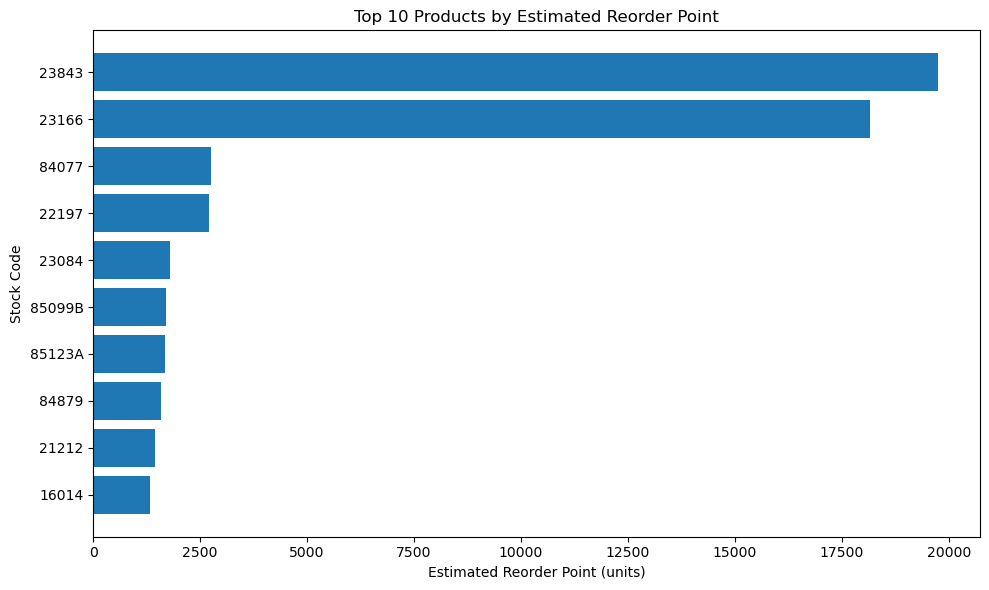

In [17]:
top_products = inventory_recommendations.head(10).sort_values(
    "Reorder_Point",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["StockCode"].astype(str),
    top_products["Reorder_Point"]
)

plt.xlabel("Estimated Reorder Point (units)")
plt.ylabel("Stock Code")
plt.title("Top 10 Products by Estimated Reorder Point")
plt.tight_layout()
plt.show()

In [18]:
output_columns = [
    "StockCode",
    "Description",
    "Total_Units_Sold",
    "Total_Revenue",
    "Average_Daily_Demand",
    "Demand_Std",
    "Active_Days",
    "Safety_Stock",
    "Reorder_Point",
    "Target_Stock_Level"
]

inventory_recommendations[output_columns].to_excel(
    r"C:\Users\MTC\Desktop\RetailPulse\data\processed\inventory_recommendations.xlsx",
    index=False
)

print("Inventory recommendations saved successfully.")

Inventory recommendations saved successfully.
